# EfficientNetV2-S — Güçlü Model ve Performans Analizi (Kişi 4)

Takımın ortak `dataset.py` dosyası kullanılır (train / valid / test, sayısal sınıf sırası).
Puanlama hocanın formülüyle hesaplanır: **0.60·Accuracy + 0.25·Hız + 0.15·Boyut** (Tmax = 50 ms, Smax = 35 MB, CPU).

1. Veri (ortak `dataset.py`)
2. Model ve eğitim fonksiyonları
3. Hyperparameter denemeleri: learning rate, batch size, optimizer
4. En iyi ayarla final eğitim → `efficientnetv2_best.pth`
5. Eğitim grafikleri
6. Test metrikleri: accuracy, precision, recall, F1
7. Confusion matrix
8. Hatalı tahmin analizi
9. CPU hızı, model boyutu, yarışma puanı → `results/efficientnetv2_metrics.json`
10. Düşük çözünürlük denemesi (192 px)
11. MobileNetV3 — aynı koşullarda yeniden ölçüm
12. Takım modelleriyle karşılaştırma

**Colab:** Runtime → Change runtime type → **T4 GPU**, sonra **Run all**. Hazırlık gerekmez:
veri seti ve `dataset.py` otomatik iner, `metrics.py` aşağıdaki hücreden oluşturulur.
Model ve sonuçlar Drive'da `MyDrive/FlowerCompetition/` klasörüne kaydedilir.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
print('GPU var mı:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU adı:', torch.cuda.get_device_name(0))

Mounted at /content/drive
GPU var mı: True
GPU adı: Tesla T4


In [2]:
# Her şey otomatik iner: veri seti (hocanın linki), dataset.py (takım reposu), cat_to_name.json
REPO = 'https://raw.githubusercontent.com/sinemsrcck/Flower-Species-Classification/main'
DRIVE_DIR = '/content/drive/MyDrive/FlowerCompetition'   # sonuçlar ve model buraya kaydedilir (yoksa oluşturulur)
!mkdir -p /content/data {DRIVE_DIR}/results
!wget -q -nc -O /content/flower_data.tar.gz https://s3.amazonaws.com/content.udacity-data.com/nd089/flower_data.tar.gz
!tar -xzf /content/flower_data.tar.gz -C /content/data
!curl -sL -o /content/dataset.py {REPO}/dataset.py
!curl -sL -o /content/data/cat_to_name.json https://raw.githubusercontent.com/udacity/aipnd-project/master/cat_to_name.json
!curl -sL -o {DRIVE_DIR}/results/efficientnet_b0_metrics.json {REPO}/results/efficientnet_b0_metrics.json
!curl -sL -o {DRIVE_DIR}/results/clip_metrics.json {REPO}/results/clip_metrics.json
!ls /content/data

cat_to_name.json  test	train  valid


In [3]:
%%writefile /content/metrics.py
"""metrics.py — Değerlendirme yardımcıları (Kişi 4).

Accuracy, precision, recall, F1, confusion matrix, eğitim grafikleri,
hatalı tahmin analizi, CPU inference hızı, model boyutu ve yarışma puanı.
"""
import json
import os
import time

import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])


@torch.no_grad()
def get_predictions(model, loader, device):
    """Bir DataLoader üzerinde (y_true, y_pred, y_prob) döndürür."""
    model.eval()
    ys, preds, probs = [], [], []
    for x, y in loader:
        out = model(x.to(device, non_blocking=True))
        p = out.softmax(1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy()


def compute_metrics(y_true, y_pred, y_prob=None, k=5):
    """Top-1 (ve varsa top-k) accuracy ile macro/weighted precision, recall, F1."""
    res = {"accuracy": accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        res.update({f"precision_{avg}": p, f"recall_{avg}": r, f"f1_{avg}": f})
    if y_prob is not None:
        topk = np.argsort(y_prob, axis=1)[:, -k:]
        res[f"top{k}_accuracy"] = float(np.mean([t in row for t, row in zip(y_true, topk)]))
    return res


def print_metrics(res):
    for k, v in res.items():
        print(f"{k:>20}: {v:.4f}")


def per_class_report(y_true, y_pred, class_names=None):
    return classification_report(y_true, y_pred, target_names=class_names, zero_division=0)


def plot_confusion_matrix(y_true, y_pred, class_names=None, normalize=True, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    if normalize:
        cm = cm.astype(float) / cm.sum(1, keepdims=True).clip(min=1)
    n = cm.shape[0]
    fig, ax = plt.subplots(figsize=(max(8, n * 0.18), max(8, n * 0.18)))
    im = ax.imshow(cm, cmap="Blues")
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek")
    ax.set_title("Confusion Matrix" + (" (normalize)" if normalize else ""))
    if class_names is not None and n <= 40:
        ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=90, fontsize=7)
        ax.set_yticks(range(n)); ax.set_yticklabels(class_names, fontsize=7)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()
    return cm


def most_confused_pairs(y_true, y_pred, class_names=None, top=15):
    """En sık karıştırılan (gerçek, tahmin) çiftleri."""
    cm = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm, 0)
    idx = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1], cm.shape))[0][:top]
    name = (lambda i: class_names[i]) if class_names else str
    return [(name(i), name(j), int(cm[i, j])) for i, j in idx if cm[i, j] > 0]


def plot_history(history, save_path=None):
    """history: {'train_loss','val_loss','train_acc','val_acc'} listeleri."""
    ep = range(1, len(history["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(ep, history["train_loss"], label="train"); a1.plot(ep, history["val_loss"], label="val")
    a1.set_title("Loss"); a1.set_xlabel("Epoch"); a1.legend()
    a2.plot(ep, history["train_acc"], label="train"); a2.plot(ep, history["val_acc"], label="val")
    a2.set_title("Accuracy"); a2.set_xlabel("Epoch"); a2.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()


def show_misclassified(dataset, y_true, y_pred, y_prob, class_names=None, n=16, save_path=None):
    """En emin olunarak yanlış tahmin edilen n örneği gösterir.
    dataset: değerlendirmede kullanılan (shuffle edilmemiş) dataset."""
    wrong = np.where(y_true != y_pred)[0]
    if len(wrong) == 0:
        print("Hatalı tahmin yok."); return []
    wrong = wrong[np.argsort(-y_prob[wrong].max(1))][:n]
    name = (lambda i: class_names[i]) if class_names else str
    cols = 4
    rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.4))
    for ax in np.array(axes).ravel():
        ax.axis("off")
    for ax, i in zip(np.array(axes).ravel(), wrong):
        img = dataset[i][0].permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN
        ax.imshow(img.clip(0, 1))
        ax.set_title(f"G: {name(y_true[i])}\nT: {name(y_pred[i])} ({y_prob[i].max():.2f})",
                     fontsize=8, color="red")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()
    return wrong.tolist()


@torch.no_grad()
def measure_cpu_latency(model, dataset, n=100, warmup=10, num_threads=1):
    """Yarışma koşullarına yakın ölçüm: CPU, batch=1, gerçek test görüntüleri.
    Kişi 1 ile aynı yöntem (100 görüntü, 10 ısınma, 1 thread).
    Döndürür: (ortalama ms, ortanca ms)."""
    old_threads = torch.get_num_threads()
    torch.set_num_threads(num_threads)
    model = model.cpu().eval()
    samples = [dataset[i][0].unsqueeze(0) for i in range(n)]
    for x in samples[:warmup]:
        model(x)
    times = []
    for x in samples:
        t = time.perf_counter()
        model(x)
        times.append((time.perf_counter() - t) * 1000)
    torch.set_num_threads(old_threads)
    return float(np.mean(times)), float(np.median(times))


def model_size_mb(path):
    return os.path.getsize(path) / 1024 ** 2


def competition_score(accuracy, ms_per_image, size_mb, t_max=50, s_max=35):
    """Hocanın formülü: 0.60*Acc + 0.25*Hız + 0.15*Boyut (accuracy 0-1 arası verilir)."""
    acc = accuracy * 100
    speed = min(100, t_max / ms_per_image * 100)
    size = min(100, s_max / size_mb * 100)
    return {"accuracy_score": acc, "speed_score": speed, "size_score": size,
            "final_score": 0.60 * acc + 0.25 * speed + 0.15 * size}


def save_metrics_json(path, model_name, accuracy, ms_per_image, size_mb, device, **extra):
    """results/<model>_metrics.json — takımın ortak şeması (generalization_tests.py --task compare)."""
    data = {"model_name": model_name, "accuracy": round(float(accuracy), 4),
            "inference_ms_per_image": round(ms_per_image, 2), "model_size_mb": round(size_mb, 2),
            "device": device}
    data.update({k: round(v, 4) if isinstance(v, float) else v for k, v in extra.items()})
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    return data


def count_params(model):
    return sum(p.numel() for p in model.parameters())

Writing /content/metrics.py


## 1. Veri — ortak `dataset.py`

In [4]:
import os, copy, json, time, random
import numpy as np
import pandas as pd
import torch.nn as nn
from torchvision import models, transforms

from dataset import get_dataloaders, NumericImageFolder, MEAN, STD
from metrics import *

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DATA_DIR = '/content/data'
RESULTS_DIR = f'{DRIVE_DIR}/results'
SAVE_PATH = f'{DRIVE_DIR}/efficientnetv2_best.pth'
os.makedirs(RESULTS_DIR, exist_ok=True)

train_loader, valid_loader, test_loader, classes = get_dataloaders(DATA_DIR, batch_size=32)
cat_to_name = json.load(open(f'{DATA_DIR}/cat_to_name.json'))
class_names = [cat_to_name[c] for c in classes]   # sınıf sırası dataset.py ile aynı (1..102)
NUM_CLASSES = len(classes)

print('Sınıf sayısı:', NUM_CLASSES)
print('Train / Valid / Test:', len(train_loader.dataset), len(valid_loader.dataset), len(test_loader.dataset))

Sınıf sayısı: 102
Train / Valid / Test: 6552 818 819


## 2. Model ve eğitim fonksiyonları
- ImageNet ağırlıklı **EfficientNetV2-S**, son katman 102 sınıfa çevrilir.
- **Fine-tuning:** gövde düşük learning rate ile, yeni son katman 10 kat yüksek learning rate ile öğrenir.
- Mixed precision (AMP), label smoothing 0.1, OneCycle learning rate, early stopping.

In [5]:
def build_model():
    m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    return m

def make_optimizer(name, model, lr, wd=1e-4):
    groups = [{'params': model.features.parameters(), 'lr': lr},
              {'params': model.classifier.parameters(), 'lr': lr * 10}]
    if name == 'adamw': return torch.optim.AdamW(groups, lr=lr, weight_decay=wd)
    if name == 'adam':  return torch.optim.Adam(groups, lr=lr)
    if name == 'sgd':   return torch.optim.SGD(groups, lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    raise ValueError(name)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def run_epoch(model, loader, optimizer=None, scheduler=None, scaler=None):
    """optimizer verilirse eğitim, verilmezse değerlendirme yapar."""
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()          # OneCycle: her batch'ten sonra
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            n += images.size(0)
    return total_loss / n, correct / n

def train_model(lr=3e-4, batch_size=32, opt_name='adamw', epochs=10, patience=4, verbose=True):
    tr_loader, va_loader, _, _ = get_dataloaders(DATA_DIR, batch_size=batch_size)
    model = build_model().to(device)
    optimizer = make_optimizer(opt_name, model, lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[lr, lr * 10], epochs=epochs, steps_per_epoch=len(tr_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=device.type == 'cuda')

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_acc, best_state, bad = 0.0, None, 0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, tr_loader, optimizer, scheduler, scaler)
        va_loss, va_acc = run_epoch(model, va_loader)
        for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
            history[k].append(v)
        note = ''
        if va_acc > best_acc:
            best_acc, best_state, bad, note = va_acc, copy.deepcopy(model.state_dict()), 0, '  ★'
        else:
            bad += 1
        if verbose:
            print(f'Epoch {epoch}/{epochs} | train acc {tr_acc:.3f} | valid acc {va_acc:.4f} | '
                  f'valid loss {va_loss:.3f} | {time.time() - t0:.0f} sn{note}')
        if bad >= patience:
            print('Early stopping'); break
    model.load_state_dict(best_state)
    return model, history, best_acc

## 3. Hyperparameter denemeleri
Her ayar kısa (3 epoch) eğitilip valid accuracy'ye bakılır. Sırayla: **learning rate → batch size → optimizer**.
(T4'te toplam ~40-50 dk. Süre kısıtlıysa denemeleri azaltabilirsiniz.)

In [6]:
hp_results = []
def trial(**kw):
    t0 = time.time()
    _, _, acc = train_model(epochs=3, patience=99, verbose=False, **kw)
    hp_results.append({**kw, 'valid_acc': acc, 'minutes': (time.time() - t0) / 60})
    print(kw, f'-> valid acc {acc:.4f}')

def best_of(key):
    return max(hp_results, key=lambda r: r['valid_acc'])[key]

# 1) Learning rate
for lr in [1e-4, 3e-4, 1e-3]:
    trial(lr=lr, batch_size=32, opt_name='adamw')
best_lr = best_of('lr')

# 2) Batch size
for bs in [16, 64]:
    trial(lr=best_lr, batch_size=bs, opt_name='adamw')
best_bs = best_of('batch_size')

# 3) Optimizer (SGD genelde daha yüksek LR ister)
trial(lr=best_lr, batch_size=best_bs, opt_name='adam')
trial(lr=best_lr * 10, batch_size=best_bs, opt_name='sgd')

hp_df = pd.DataFrame(hp_results).sort_values('valid_acc', ascending=False)
hp_df.to_csv(f'{RESULTS_DIR}/efficientnetv2_hparams.csv', index=False)
hp_df

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 154MB/s]


{'lr': 0.0001, 'batch_size': 32, 'opt_name': 'adamw'} -> valid acc 0.9853
{'lr': 0.0003, 'batch_size': 32, 'opt_name': 'adamw'} -> valid acc 0.9853
{'lr': 0.001, 'batch_size': 32, 'opt_name': 'adamw'} -> valid acc 0.9939
{'lr': 0.001, 'batch_size': 16, 'opt_name': 'adamw'} -> valid acc 0.9890
{'lr': 0.001, 'batch_size': 64, 'opt_name': 'adamw'} -> valid acc 0.9914
{'lr': 0.001, 'batch_size': 32, 'opt_name': 'adam'} -> valid acc 0.9878
{'lr': 0.01, 'batch_size': 32, 'opt_name': 'sgd'} -> valid acc 0.9829


,lr,batch_size,opt_name,valid_acc,minutes
2,0.0010,32,adamw,0.993888,3.977943
4,0.0010,64,adamw,0.991443,3.727437
3,0.0010,16,adamw,0.988998,4.648506
5,0.0010,32,adam,0.987775,3.942841
0,0.0001,32,adamw,0.985330,4.015982
1,0.0003,32,adamw,0.985330,3.950449
6,0.0100,32,sgd,0.982885,3.896727


## 4. En iyi ayarla final eğitim

In [7]:
best = hp_df.iloc[0]
print('En iyi ayar:', best.to_dict())

model, history, best_valid = train_model(lr=best['lr'], batch_size=int(best['batch_size']),
                                         opt_name=best['opt_name'], epochs=20, patience=5)
print(f'En iyi valid accuracy: {best_valid:.4f}')

# Kişi 2'nin predict.py / evaluate.py checkpoint formatı. Ağırlıklar FP16 → dosya ~yarı boyut.
# CPU'da load_state_dict FP16 değerleri modelin FP32 ağırlıklarına otomatik çevirir.
class_to_idx = {c: i for i, c in enumerate(classes)}   # "1"→0 ... "102"→101 (dataset.py)
torch.save({'architecture': 'efficientnet_v2_s', 'class_to_idx': class_to_idx, 'image_size': 224,
            'precision': 'fp16', 'valid_accuracy': best_valid * 100,
            'model_state_dict': {k: v.half() if v.is_floating_point() else v
                                 for k, v in model.state_dict().items()}}, SAVE_PATH)
print(f'Kaydedildi: {SAVE_PATH} ({model_size_mb(SAVE_PATH):.1f} MB)')

En iyi ayar: {'lr': 0.001, 'batch_size': 32, 'opt_name': 'adamw', 'valid_acc': 0.9938875305623472, 'minutes': 3.9779433568318683}
Epoch 1/20 | train acc 0.577 | valid acc 0.9340 | valid loss 1.076 | 77 sn  ★
Epoch 2/20 | train acc 0.905 | valid acc 0.9230 | valid loss 1.158 | 78 sn
Epoch 3/20 | train acc 0.891 | valid acc 0.9230 | valid loss 1.167 | 78 sn
Epoch 4/20 | train acc 0.942 | valid acc 0.9462 | valid loss 1.058 | 79 sn  ★
Epoch 5/20 | train acc 0.971 | valid acc 0.9719 | valid loss 0.943 | 79 sn  ★
Epoch 6/20 | train acc 0.984 | valid acc 0.9633 | valid loss 0.955 | 79 sn
Epoch 7/20 | train acc 0.980 | valid acc 0.9499 | valid loss 1.017 | 79 sn
Epoch 8/20 | train acc 0.979 | valid acc 0.9670 | valid loss 0.992 | 79 sn
Epoch 9/20 | train acc 0.984 | valid acc 0.9743 | valid loss 0.922 | 79 sn  ★
Epoch 10/20 | train acc 0.990 | valid acc 0.9756 | valid loss 0.892 | 79 sn  ★
Epoch 11/20 | train acc 0.994 | valid acc 0.9792 | valid loss 0.889 | 79 sn  ★
Epoch 12/20 | train acc 0

## 5. Eğitim grafikleri

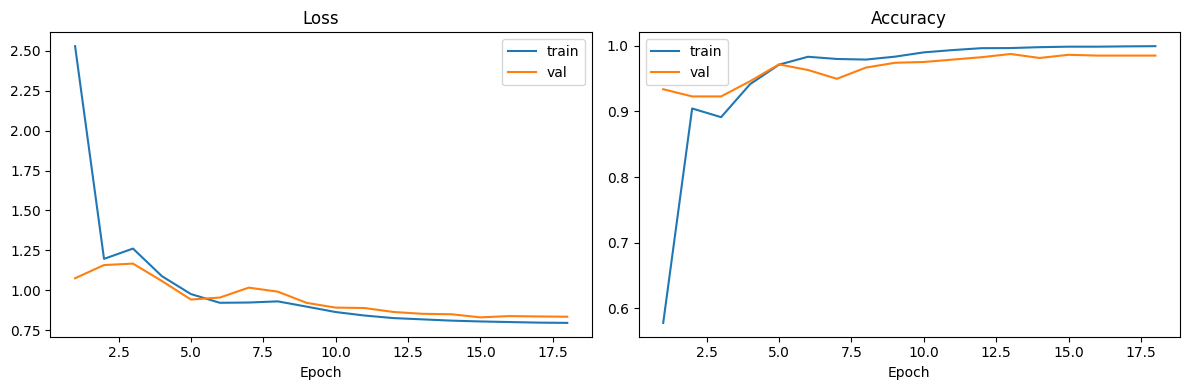

In [8]:
plot_history(history, save_path=f'{RESULTS_DIR}/efficientnetv2_training.png')

## 6. Test metrikleri — accuracy, precision, recall, F1

In [9]:
# Kaydedilen FP16 dosyadan yükleyip ölçüyoruz → teslim edilen dosyanın gerçek sonucu
model = build_model()
model.load_state_dict(torch.load(SAVE_PATH, map_location='cpu', weights_only=True)['model_state_dict'])
model = model.to(device).eval()

y_true, y_pred, y_prob = get_predictions(model, test_loader, device)
test_res = compute_metrics(y_true, y_pred, y_prob)
print_metrics(test_res)
print()
print(per_class_report(y_true, y_pred, class_names))

            accuracy: 0.9817
     precision_macro: 0.9796
        recall_macro: 0.9825
            f1_macro: 0.9787
  precision_weighted: 0.9851
     recall_weighted: 0.9817
         f1_weighted: 0.9815
       top5_accuracy: 1.0000

                           precision    recall  f1-score   support

            pink primrose       1.00      0.80      0.89         5
hard-leaved pocket orchid       1.00      1.00      1.00         5
         canterbury bells       1.00      1.00      1.00         2
                sweet pea       1.00      1.00      1.00         6
         english marigold       1.00      1.00      1.00         4
               tiger lily       1.00      0.89      0.94         9
              moon orchid       1.00      1.00      1.00         6
         bird of paradise       1.00      1.00      1.00        10
                monkshood       1.00      1.00      1.00         2
            globe thistle       1.00      1.00      1.00         3
               snapdragon    

## 7. Confusion matrix

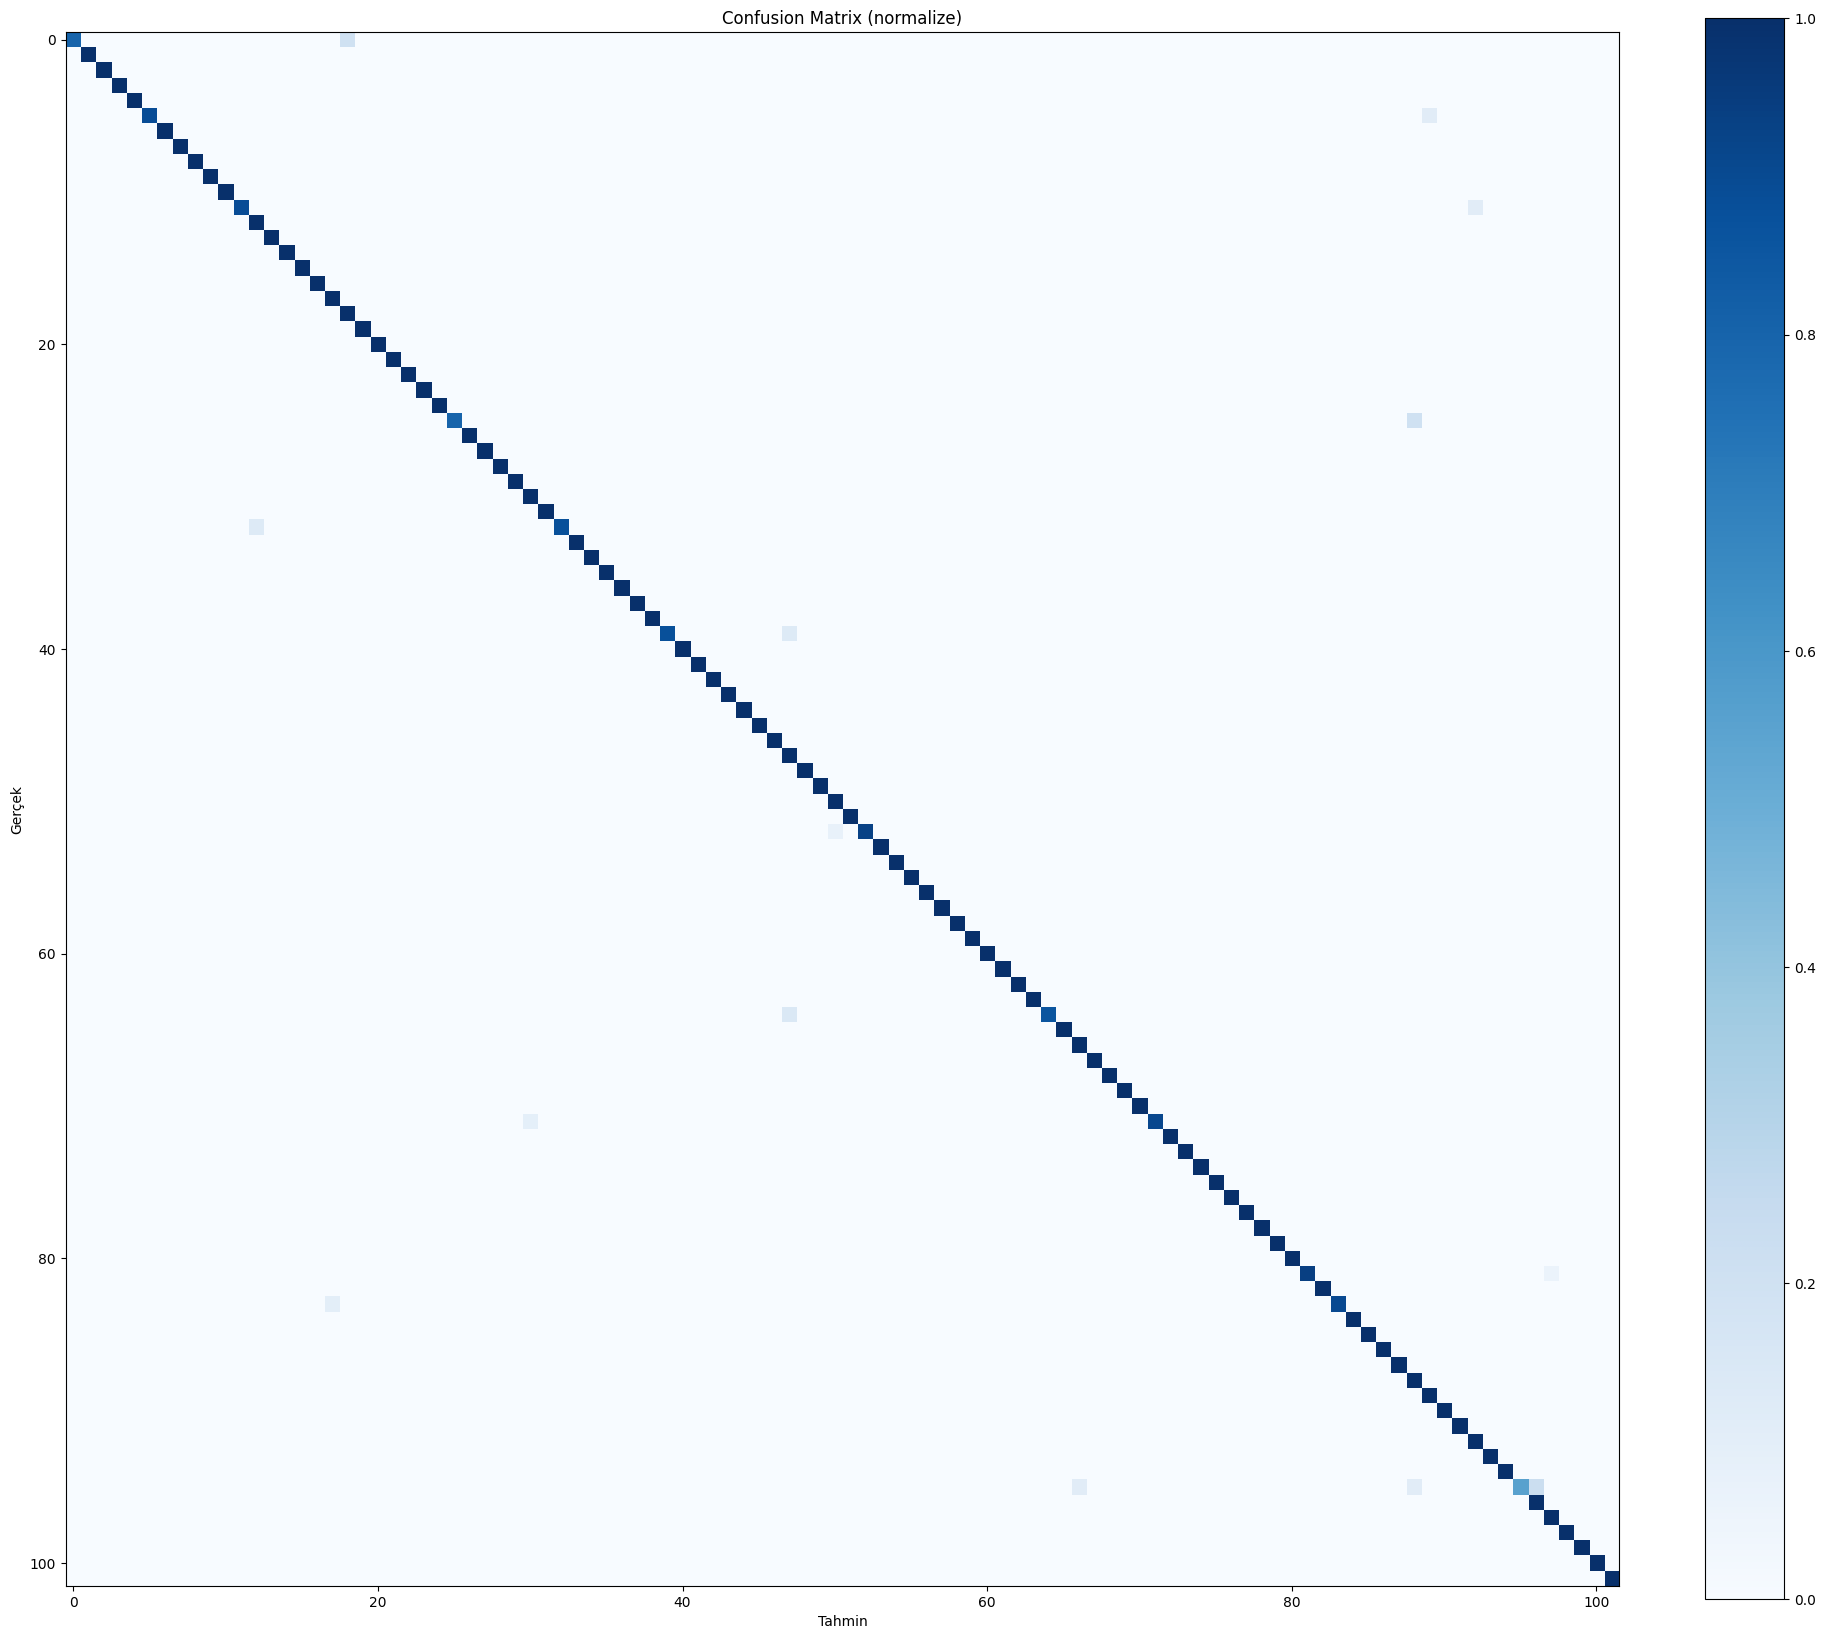

En çok karıştırılan türler (gerçek → tahmin: adet):
  camellia → mallow: 2
  pink primrose → balloon flower: 1
  primula → petunia: 1
  corn poppy → watercress: 1
  californian poppy → buttercup: 1
  tiger lily → canna lily: 1
  columbine → peruvian lily: 1
  camellia → watercress: 1
  azalea → carnation: 1
  clematis → mexican petunia: 1
  colt's foot → ball moss: 1
  lenten rose → buttercup: 1
  love in the mist → king protea: 1
  camellia → spring crocus: 1


In [10]:
cm = plot_confusion_matrix(y_true, y_pred, class_names, save_path=f'{RESULTS_DIR}/efficientnetv2_confusion_matrix.png')

confused = most_confused_pairs(y_true, y_pred, class_names)
print('En çok karıştırılan türler (gerçek → tahmin: adet):')
for t, p, c in confused:
    print(f'  {t} → {p}: {c}')

## 8. Hatalı tahmin analizi
Modelin **emin olduğu halde yanıldığı** örnekler (G = gerçek, T = tahmin, parantezde güven).

In [11]:
wrong_idx = show_misclassified(test_loader.dataset, y_true, y_pred, y_prob, class_names, n=16,
                               save_path=f'{RESULTS_DIR}/efficientnetv2_errors.png')

per_class_recall = cm.diagonal()
worst = np.argsort(per_class_recall)[:10]
print('Recall değeri en düşük 10 tür:')
for i in worst:
    print(f'  {class_names[i]:30s} recall={per_class_recall[i]:.2f}')

print(f'\nToplam hatalı tahmin: {int((y_true != y_pred).sum())} / {len(y_true)}')

Output hidden; open in https://colab.research.google.com to view.

**Yorum — hatalı tahmin analizi**

Test setinde 819 görüntüden **15 hata** var (%98.17 accuracy, top-5 %100). Hataların hepsi farklı türlere dağılmış; tek tekrarlayan sorun camellia.

- **En zor tür: camellia** (recall 0.56, 9 görüntüden 4'ü yanlış: mallow ×2, watercress, spring crocus). Camellia veri setinde kırmızı, beyaz, alacalı renklerde ve hem tek hem katmerli formda görünüyor; renk ipucu tutarsız olduğu için model yaprak dizilimine güvenmek zorunda kalıyor. En emin olunan hata da burada: camellia → mallow (0.93). İki türde de kupa şeklinde açılan geniş yapraklar ve ortada belirgin bir stamen kümesi var.
- **Renk + şekil benzerliği:** kırmızı, ince yapraklı çiçekler (corn poppy → watercress, azalea → carnation, primula → petunia), sarı-turuncu kupa şeklindeki çiçekler (californian poppy → buttercup) ve beyaz, sarı merkezli çiçekler (lenten rose → buttercup) birbirine karışıyor. Model özellikle baskın renk ve genel silüet benzer olduğunda zorlanıyor.
- **Alışılmadık açı / kadraj:** colt's foot yandan ve yarı kapalı çekildiği için ball moss sanılmış; tiger lily'nin kıvrık yaprakları yakın plandan canna lily'ye benziyor; love in the mist üstten değil yandan, ipliksi yapısı öne çıkacak şekilde çekildiği için king protea ile karışmış.
- **Güven değerleri:** 15 hatanın 10'unda modelin güveni %60'ın altında. Model yanıldığında çoğunlukla emin değil; düşük güvenli tahminler "belirsiz" olarak işaretlenebilir. Top-5 accuracy %100 olduğu için doğru tür her zaman ilk 5 tahmin içinde.
- **Eğitim grafiği:** train ve valid eğrileri birbirine yakın, valid loss ~0.83'te sabitleniyor; belirgin overfitting yok. En iyi valid accuracy 13. epoch'ta (%98.78), 18. epoch'ta early stopping.
- **Yarışma açısından:** accuracy yüksek ama model büyük (39.3 MB) ve CPU'da yavaş (119.6 ms) → tahmini puan 82.72. 192 px girişte hem accuracy (%98.5) hem puan (86.86) artıyor. EfficientNet-B0 (%99.02, 41.6 ms, 16 MB, ~99.4 puan) bu veri setinde daha uygun; EfficientNetV2-S takımın üst-sınır referans modeli olarak kalıyor.

## 9. CPU hızı, model boyutu ve yarışma puanı
Kişi 1 ile **aynı yöntem**: CPU, 1 thread, batch = 1, 100 test görüntüsü, 10 ısınma.

In [12]:
cpu_model = copy.deepcopy(model).cpu().eval()
ms_mean, ms_median = measure_cpu_latency(cpu_model, test_loader.dataset)
size_mb = model_size_mb(SAVE_PATH)
score = competition_score(test_res['accuracy'], ms_mean, size_mb)

print(f'Parametre: {count_params(cpu_model)/1e6:.1f} M')
print(f'CPU: {ms_mean:.1f} ms/foto (ortanca {ms_median:.1f}) | Dosya: {size_mb:.2f} MB')
print(f"Accuracy puanı: {score['accuracy_score']:.2f} | Hız puanı: {score['speed_score']:.1f} | "
      f"Boyut puanı: {score['size_score']:.1f}")
print(f"Tahmini final puan: {score['final_score']:.2f} / 100")

metrics_json = save_metrics_json(
    f'{RESULTS_DIR}/efficientnetv2_metrics.json',
    model_name='EfficientNetV2-S (fine-tuned)',
    accuracy=test_res['accuracy'], ms_per_image=ms_mean, size_mb=size_mb,
    device='cpu (Colab, 1 thread)', num_test_images=len(y_true),
    best_valid_accuracy=best_valid, top5_accuracy=test_res['top5_accuracy'],
    precision_macro=test_res['precision_macro'], recall_macro=test_res['recall_macro'],
    f1_macro=test_res['f1_macro'], estimated_final_score=score['final_score'],
    best_hparams={'lr': float(best['lr']), 'batch_size': int(best['batch_size']), 'optimizer': best['opt_name']},
)
print(json.dumps(metrics_json, indent=2, ensure_ascii=False))

Parametre: 20.3 M
CPU: 119.6 ms/foto (ortanca 117.3) | Dosya: 39.28 MB
Accuracy puanı: 98.17 | Hız puanı: 41.8 | Boyut puanı: 89.1
Tahmini final puan: 82.72 / 100
{
  "model_name": "EfficientNetV2-S (fine-tuned)",
  "accuracy": 0.9817,
  "inference_ms_per_image": 119.62,
  "model_size_mb": 39.28,
  "device": "cpu (Colab, 1 thread)",
  "num_test_images": 819,
  "best_valid_accuracy": 0.9878,
  "top5_accuracy": 1.0,
  "precision_macro": 0.9796,
  "recall_macro": 0.9825,
  "f1_macro": 0.9787,
  "estimated_final_score": 82.7178,
  "best_hparams": {
    "lr": 0.001,
    "batch_size": 32,
    "optimizer": "adamw"
  }
}


## 10. Düşük çözünürlük denemesi (192 px)
Aynı model, yeniden eğitim yapmadan 192×192 girişle test edilir.
Hız kazancı accuracy kaybına değiyor mu? (Hoca giriş çözünürlüğünü sabitlerse bu deneme yalnızca analiz amaçlıdır.)

In [13]:
from torch.utils.data import DataLoader

res_rows = [{'img_size': 224, 'accuracy': test_res['accuracy'], 'ms': ms_mean, **score}]
for size in [192]:
    tf = transforms.Compose([transforms.Resize(int(size * 256 / 224)), transforms.CenterCrop(size),
                             transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    ds = NumericImageFolder(f'{DATA_DIR}/test', transform=tf)
    yt, yp, _ = get_predictions(model, DataLoader(ds, batch_size=64, num_workers=2), device)
    acc = float((yt == yp).mean())
    ms, _ = measure_cpu_latency(copy.deepcopy(model).cpu(), ds)
    res_rows.append({'img_size': size, 'accuracy': acc, 'ms': ms, **competition_score(acc, ms, size_mb)})

res_df = pd.DataFrame(res_rows).round(3)
res_df.to_csv(f'{RESULTS_DIR}/efficientnetv2_resolution.csv', index=False)
res_df

,img_size,accuracy,ms,accuracy_score,speed_score,size_score,final_score
0,224,0.982,119.615,98.168,41.801,89.11,82.718
1,192,0.985,87.002,98.535,57.470,89.11,86.855


## 11. MobileNetV3 (Kişi 2) — aynı koşullarda yeniden ölçüm
Kişi 2'nin sonuçları valid setinde ve GPU'da ölçülmüştü. Adil karşılaştırma için `mobilenetv3_fp16.pth`
burada **test setinde** ve **aynı CPU yöntemiyle** (1 thread, batch = 1) ölçülür.
Dosya Drive'da `FlowerCompetition/` klasöründe yoksa hücre bilgisayarından seçmeni ister.

In [ ]:
from torchvision.models import mobilenet_v3_large

MB_PATH = f'{DRIVE_DIR}/mobilenetv3_fp16.pth'
if not os.path.exists(MB_PATH):
    from google.colab import files
    print('mobilenetv3_fp16.pth dosyasını seç:')
    uploaded = files.upload()
    MB_PATH = '/content/' + next(iter(uploaded))

mb_ckpt = torch.load(MB_PATH, map_location='cpu', weights_only=True)
assert mb_ckpt['class_to_idx'] == {c: i for i, c in enumerate(classes)}, 'Sınıf sırası dataset.py ile uyuşmuyor!'

mb_model = mobilenet_v3_large(weights=None)
mb_model.classifier[3] = nn.Linear(mb_model.classifier[3].in_features, NUM_CLASSES)
mb_model.load_state_dict(mb_ckpt['model_state_dict'])   # FP16 → FP32 (predict.py'nin CPU davranışı)
mb_model = mb_model.to(device).eval()

mb_true, mb_pred, mb_prob = get_predictions(mb_model, test_loader, device)
mb_res = compute_metrics(mb_true, mb_pred, mb_prob)
mb_ms, _ = measure_cpu_latency(copy.deepcopy(mb_model), test_loader.dataset)
mb_size = model_size_mb(MB_PATH)
mb_score = competition_score(mb_res['accuracy'], mb_ms, mb_size)
print_metrics(mb_res)
print(f"CPU: {mb_ms:.1f} ms/foto | Dosya: {mb_size:.2f} MB | Tahmini puan: {mb_score['final_score']:.2f}")

save_metrics_json(
    f'{RESULTS_DIR}/mobilenet_v3_metrics.json',
    model_name='MobileNetV3-Large (fp16, Kişi 2)',
    accuracy=mb_res['accuracy'], ms_per_image=mb_ms, size_mb=mb_size,
    device='cpu (Colab, 1 thread)', num_test_images=len(mb_true),
    precision_macro=mb_res['precision_macro'], recall_macro=mb_res['recall_macro'],
    f1_macro=mb_res['f1_macro'], estimated_final_score=mb_score['final_score'],
    note='Kişi 4 tarafından test setinde yeniden ölçüldü')

mobilenetv3_fp16.pth dosyasını seç:


## 12. Takım modelleriyle karşılaştırma
`results/*_metrics.json` dosyalarının hepsi okunur, hocanın formülüyle puanlanır.

In [ ]:
import glob
rows = []
for f in sorted(glob.glob(f'{RESULTS_DIR}/*_metrics.json')):
    m = json.load(open(f))
    s = competition_score(m['accuracy'], m['inference_ms_per_image'], m['model_size_mb'])
    rows.append({'model': m['model_name'], 'accuracy': m['accuracy'], 'ms/foto': m['inference_ms_per_image'],
                 'MB': m['model_size_mb'], 'cihaz': m.get('device', ''), 'tahmini puan': round(s['final_score'], 2)})
pd.DataFrame(rows).sort_values('tahmini puan', ascending=False)

## Modeli yükleme (Kişi 2 — `predict.py` için)
```python
import torch, torch.nn as nn
from torchvision import models

model = models.efficientnet_v2_s()
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 102)
ckpt = torch.load('efficientnetv2_best.pth', map_location='cpu', weights_only=True)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
# Format Kişi 2'nin MobileNet checkpoint'iyle aynı: architecture, class_to_idx, precision, model_state_dict.
# predict.py'de architecture == 'efficientnet_v2_s' için bu model kurulumu eklenmeli.
# Preprocessing: Resize 256, CenterCrop 224, ImageNet normalize (predict.py ile aynı)
```